In [ ]:
import torch 
import math
import numpy as np 
import matplotlib.pyplot as plt 

from torch import nn
from tqdm import tqdm

In [ ]:
class NeuralNetwork(nn.Module):

    activation_fn: callable

    def __init__(self, arq, activation_fn):

        super(NeuralNetwork, self).__init__()

        self.activation_fn = activation_fn

        self.neural_network = nn.ModuleList()
        
        for i in range(len(arq)-1):
            
            self.neural_network.append(nn.Linear(arq[i], arq[i+1]))
            nn.init.xavier_normal_(self.neural_network[i].weight)

    
    def forward(self, x):

        for layer in self.neural_network[:-1]: x = self.activation_fn(layer(x))
        x = self.neural_network[-1](x)  
        return x
    
    def save(self, local: str):

        torch.save(self.state_dict(), local)

    def load(self, local: str):

        self.load_state_dict(torch.load(local))

In [ ]:
class IPINN:

    def __init__(self, model: NeuralNetwork, d_init: float = 1e-2):

        self.model = model 
        self.log_d = nn.Parameter(torch.tensor(math.log(d_init)))

    def data_loss(self, data_input: torch.Tensor, data_target: torch.Tensor):

        return torch.mean((self.model(data_input) - data_target)**2)

    def residual_loss(self, collocation_points: torch.Tensor):

        # Ordem das colunas de entrada: 0 = t, 1 = x, 2 = y
        input = collocation_points.clone().requires_grad_(True)
        u = self.model(input)

        grads = torch.autograd.grad(u, input, torch.ones_like(u), create_graph=True)[0]
        u_t, u_x, u_y = grads[:, 0], grads[:, 1], grads[:, 2]

        # CORRECAO: segundas derivadas puras (x -> coluna 1, y -> coluna 2).
        # Antes: colunas 0 e 1, que davam derivadas mistas (u_xt e u_yx).
        u_xx = torch.autograd.grad(u_x, input, torch.ones_like(u_x), create_graph=True)[0][:, 1]
        u_yy = torch.autograd.grad(u_y, input, torch.ones_like(u_y), create_graph=True)[0][:, 2]
        
        D = torch.exp(self.log_d)
        residual = u_t - D * (u_xx + u_yy) - u.squeeze(-1)
        return torch.mean(residual**2)

    def fit(self, trainning_data: dict, epochs: int = 1_000, learning_rates: list[float] = [1e-3, 1e-2], device: str = 'cpu',
            seed: int | None = None, resample_fn=None, resample_every: int = 0):
        """
        seed: se informado, fixa a semente (reprodutibilidade entre repeticoes).
        resample_fn: funcao opcional sem argumentos que devolve novos pontos de colocacao
                     (tensor N x 3); usada a cada `resample_every` epocas (0 = desligado).
        """

        if seed is not None:
            torch.manual_seed(seed)
            
        self.model = self.model.to(device)
        self.log_d = nn.Parameter(self.log_d.detach().to(device))

        optim_model = torch.optim.AdamW(self.model.parameters(), lr = learning_rates[0], weight_decay = 0.0)
        optim_param = torch.optim.Adam([self.log_d], lr = learning_rates[1])
        scheduler_param = torch.optim.lr_scheduler.CosineAnnealingLR(optim_param, T_max = epochs, eta_min = 1e-6)
        scheduler_model = torch.optim.lr_scheduler.CosineAnnealingLR(optim_model, T_max = epochs, eta_min = 1e-6)

        data_input_obs = trainning_data['experimental_input'].to(device)
        data_target_obs = trainning_data['experimental_target'].to(device)
        data_input_ic = trainning_data['ic_input'].to(device)
        data_target_ic = trainning_data['ic_target'].to(device)
        collocation_data = trainning_data['collocation_data'].to(device)

        history = {'loss': [], 'data_loss': [], 'residual_loss': [], 'ic_loss': [], 'dl': []}
        for epoch in tqdm(range(epochs)):

            if resample_fn is not None and resample_every > 0 and epoch > 0 and epoch % resample_every == 0:
                collocation_data = resample_fn().to(device)

            optim_model.zero_grad()
            optim_param.zero_grad()
            
            data_loss_value = self.data_loss(data_input_obs, data_target_obs)
            ic_loss_value = self.data_loss(data_input_ic, data_target_ic)
            residual_loss_value = self.residual_loss(collocation_data)
            loss = data_loss_value + ic_loss_value + residual_loss_value
            
            loss.backward()
            optim_model.step()
            optim_param.step()
            scheduler_param.step()
            scheduler_model.step()

            history['loss'].append(loss.item())
            history['data_loss'].append(data_loss_value.item())
            history['residual_loss'].append(residual_loss_value.item())
            history['ic_loss'].append(ic_loss_value.item())
            history['dl'].append(torch.exp(self.log_d).item())

        return history

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


In [5]:
import time 
import numpy as np

collocation_points_size = 1_000
epochs = 10_000
proporcao = 1.

model = NeuralNetwork(
    [3] + 3 * [256] + [1],
    nn.Tanh()
)

inverse_pinn = IPINN(
    model
)

# Carregando os dados simulados por diferenças finitas
dados = np.load('../dados/numericos/data_002.npz')
input = dados['input']
target = dados['target']
param = dados['parameters']
data_total_size = input.shape[0]

quantidade_dados = round(proporcao * data_total_size)

# Filtrando uma amostra aleatória de 1.000 dados experimentais para treinamento
idx = np.random.choice(range(data_total_size), size = quantidade_dados, replace = False)

# Convertendo os dados para tensores do PyTorch
data_input_obs = torch.from_numpy(input[idx]).float().to(device)
data_target_obs = torch.from_numpy(target[idx]).float().to(device)
#print(data_input_obs.shape, data_target_obs.shape)

# Definindo dados para condição inicial conhecida
data_input_ic = torch.from_numpy(input[:2500]).float().to(device)
data_target_ic = torch.from_numpy(target[:2500]).float().to(device)

# Definindo os pontos de colocation para o cálculo do resíduo da equação diferencial residual
x = torch.FloatTensor(collocation_points_size).uniform_(0, 1)
y = torch.FloatTensor(collocation_points_size).uniform_(0, 1)
t = torch.FloatTensor(collocation_points_size).uniform_(0, 1)

collocation_data = torch.vstack([t, x, y]).T.requires_grad_(True).to(device)

# Agrupando dados de treinamento
trainning_data = {
    'experimental_input': data_input_obs,
    'experimental_target': data_target_obs,
    'ic_input': data_input_ic,
    'ic_target': data_target_ic,
    'collocation_data': collocation_data
}

inicio = time.perf_counter()
history = inverse_pinn.fit(
    trainning_data,
    epochs,
    device = device
)
fim = time.perf_counter()

# Verificando proporção dos dados utilizada
print(f'Proporção dos Dados: {proporcao:.2%}')

# Verificando tempo de treinamento
h, resto = divmod(int(fim - inicio), 3600)
m, s = divmod(resto, 60)
print(f'Tempo de Treinamento: {h}h {m}m {s}seg')

# Verificando precisão da inferência de D*
dl_estimado = torch.exp(inverse_pinn.log_d).item()
dl_ref = (param[0] / (param[1] * param[2] ** 2)).item()
erro = np.linalg.norm(dl_estimado - dl_ref) / np.linalg.norm(dl_ref)
print(f'Erro: {erro:.2%}    Estimado: {dl_estimado:.7f}     Referência: {dl_ref:.7f}')

print('-' * 50)

  0%|          | 0/10000 [00:00<?, ?it/s]c:\Users\rique\OneDrive\Documentos 1\Doutorado\Disciplina Deep Learning\modelo_adimensionalizado\env\Lib\site-packages\torch\autograd\graph.py:1113: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:702.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
100%|██████████| 10000/10000 [06:52<00:00, 24.26it/s]

Proporção dos Dados: 100.00%
Tempo de Treinamento: 0h 6m 54seg
Erro: 0.22%    Estimado: 0.0079091     Referência: 0.0079268
--------------------------------------------------


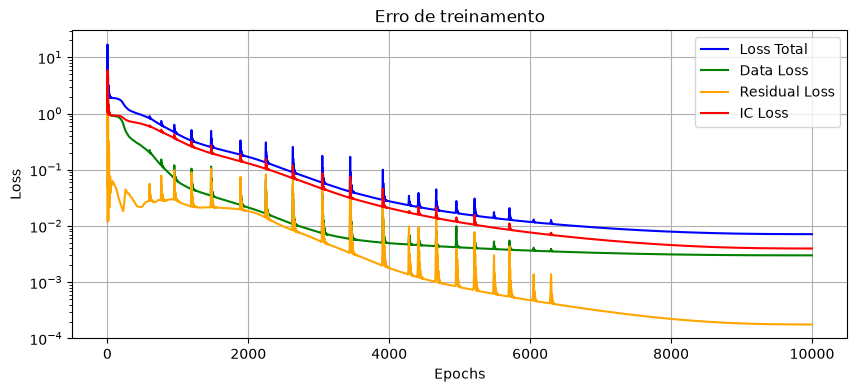

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(history['loss'], label='Loss Total', color='blue')
plt.plot(history['data_loss'], label='Data Loss', color='green')
plt.plot(history['residual_loss'], label='Residual Loss', color='orange')
plt.plot(history['ic_loss'], label='IC Loss', color='red')
plt.yscale('log')
plt.title('Erro de treinamento')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid()
plt.legend()
plt.show()

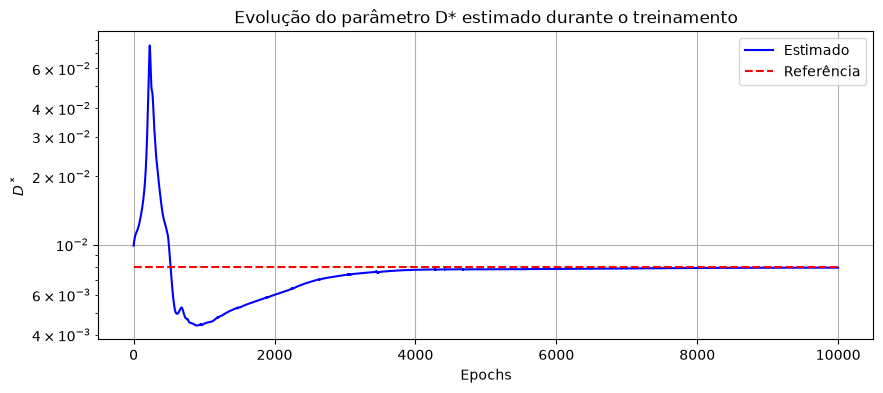

In [7]:
plt.figure(figsize=(10, 4))
plt.plot(history['dl'], label = r'Estimado', color='blue')
plt.hlines(dl_ref, 0, len(history['dl']), colors='red', linestyles='dashed', label= r'Referência')
plt.yscale('log')
plt.title('Evolução do parâmetro D* estimado durante o treinamento')
plt.xlabel('Epochs')
plt.ylabel(r'$D^*$')
plt.grid()
plt.legend()
plt.show()

In [8]:
input_tensor = torch.from_numpy(input).float().to(device)
with torch.no_grad(): pred = model(input_tensor).cpu().detach().numpy().reshape(80, 50, 50)

target = target.reshape(80, 50, 50)

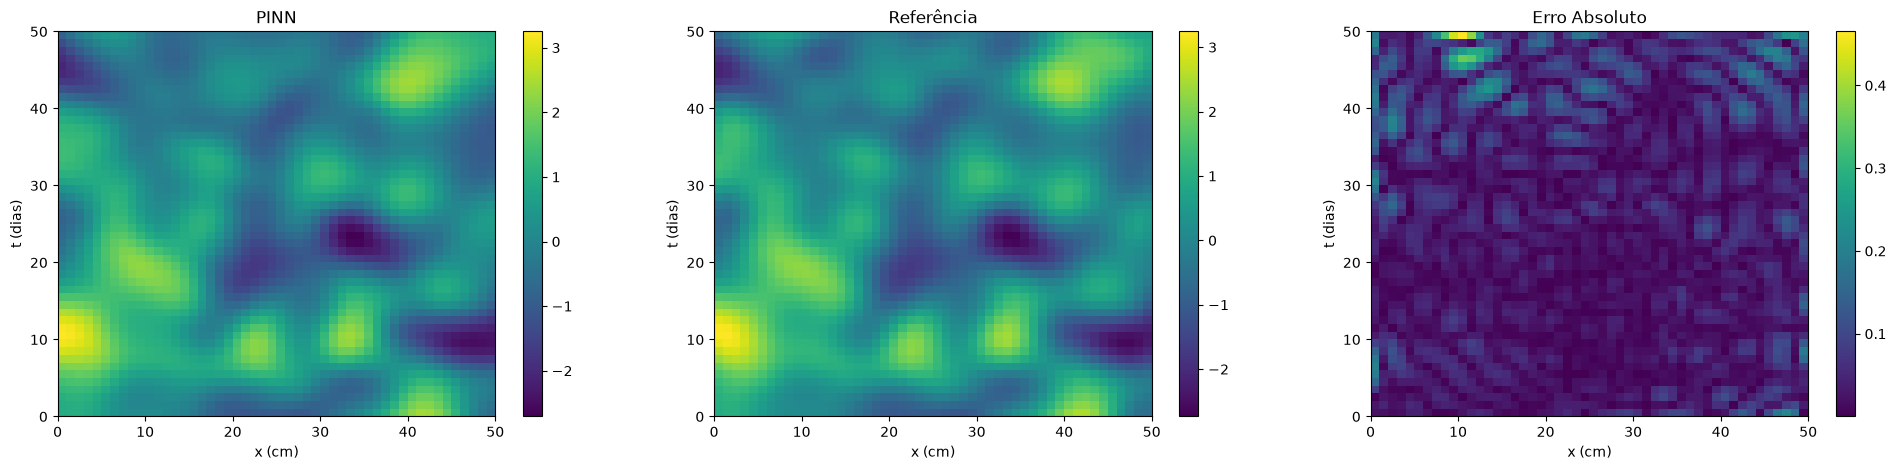

In [10]:
index = 0
fig, ax = plt.subplots(ncols = 3, figsize = (24, 5))

p0 = ax[0].pcolormesh(pred[index])
p1 = ax[1].pcolormesh(target[index])
p2 = ax[2].pcolormesh(np.abs(target[index] - pred[index]))

ax[0].set_xlabel('x (cm)')
ax[0].set_ylabel('t (dias)')
ax[0].set_title('PINN')

ax[1].set_xlabel('x (cm)')
ax[1].set_ylabel('t (dias)')
ax[1].set_title('Referência')

ax[2].set_xlabel('x (cm)')
ax[2].set_ylabel('t (dias)')
ax[2].set_title('Erro Absoluto')

plt.colorbar(p0)
plt.colorbar(p1)
plt.colorbar(p2)
plt.show()

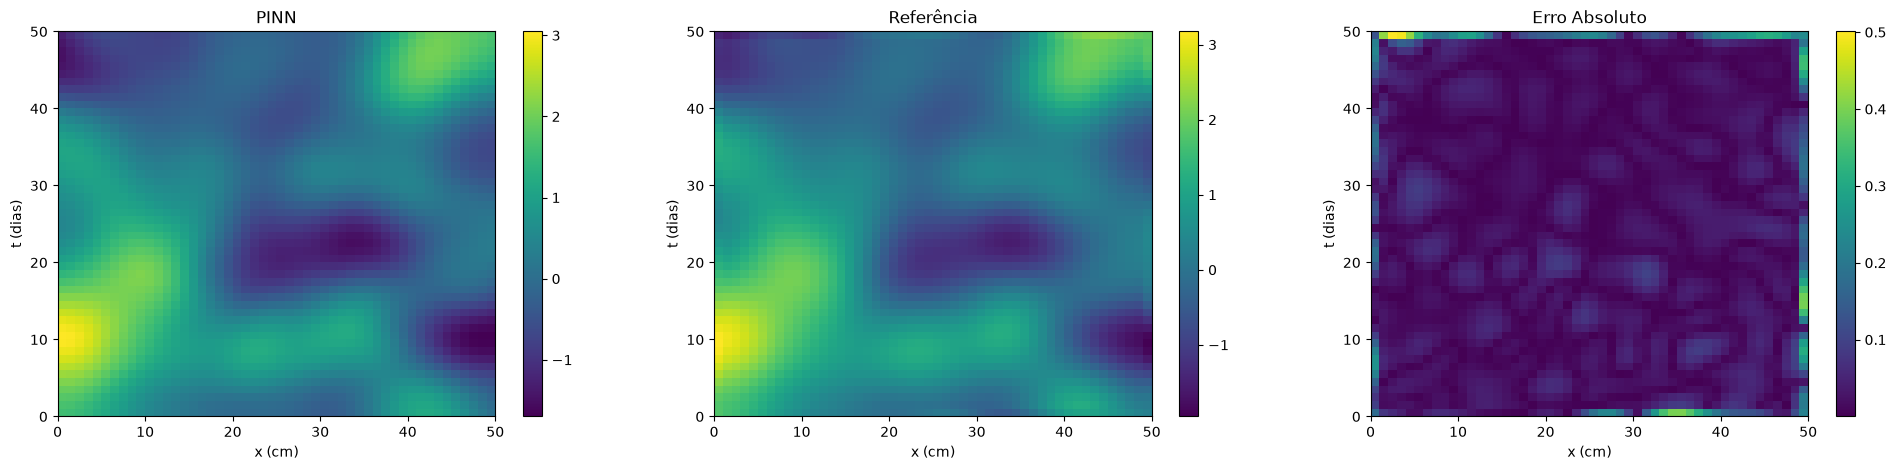

In [9]:
index = 25
fig, ax = plt.subplots(ncols = 3, figsize = (24, 5))

p0 = ax[0].pcolormesh(pred[index])
p1 = ax[1].pcolormesh(target[index])
p2 = ax[2].pcolormesh(np.abs(target[index] - pred[index]))

ax[0].set_xlabel('x (cm)')
ax[0].set_ylabel('t (dias)')
ax[0].set_title('PINN')

ax[1].set_xlabel('x (cm)')
ax[1].set_ylabel('t (dias)')
ax[1].set_title('Referência')

ax[2].set_xlabel('x (cm)')
ax[2].set_ylabel('t (dias)')
ax[2].set_title('Erro Absoluto')

plt.colorbar(p0)
plt.colorbar(p1)
plt.colorbar(p2)
plt.show()

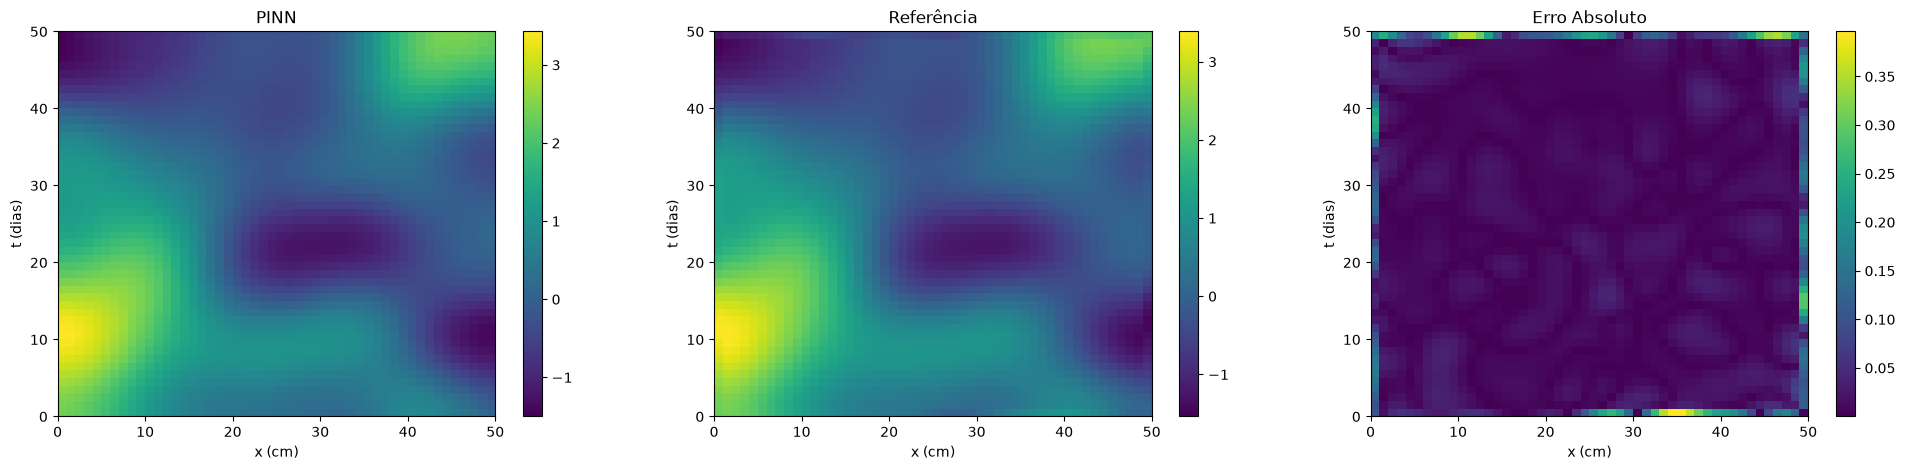

In [11]:
index = 50
fig, ax = plt.subplots(ncols = 3, figsize = (24, 5))

p0 = ax[0].pcolormesh(pred[index])
p1 = ax[1].pcolormesh(target[index])
p2 = ax[2].pcolormesh(np.abs(target[index] - pred[index]))

ax[0].set_xlabel('x (cm)')
ax[0].set_ylabel('t (dias)')
ax[0].set_title('PINN')

ax[1].set_xlabel('x (cm)')
ax[1].set_ylabel('t (dias)')
ax[1].set_title('Referência')

ax[2].set_xlabel('x (cm)')
ax[2].set_ylabel('t (dias)')
ax[2].set_title('Erro Absoluto')

plt.colorbar(p0)
plt.colorbar(p1)
plt.colorbar(p2)
plt.show()

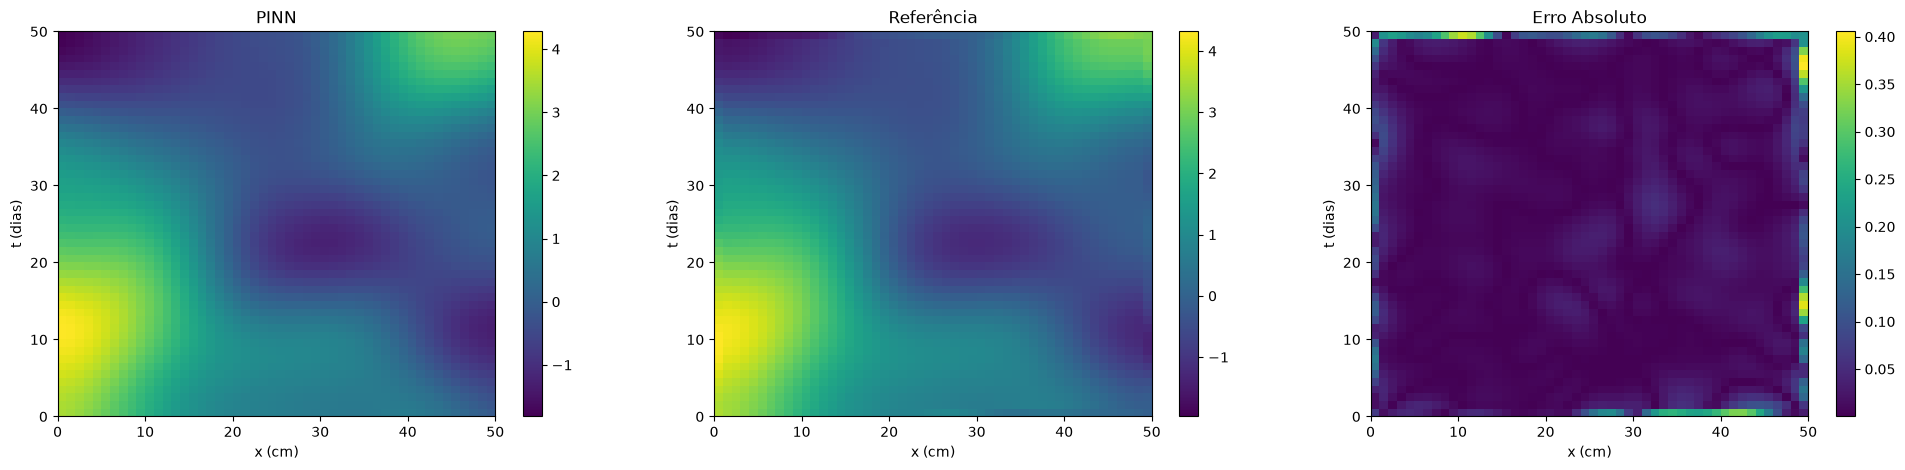

In [12]:
index = -1
fig, ax = plt.subplots(ncols = 3, figsize = (24, 5))

p0 = ax[0].pcolormesh(pred[index])
p1 = ax[1].pcolormesh(target[index])
p2 = ax[2].pcolormesh(np.abs(target[index] - pred[index]))

ax[0].set_xlabel('x (cm)')
ax[0].set_ylabel('t (dias)')
ax[0].set_title('PINN')

ax[1].set_xlabel('x (cm)')
ax[1].set_ylabel('t (dias)')
ax[1].set_title('Referência')

ax[2].set_xlabel('x (cm)')
ax[2].set_ylabel('t (dias)')
ax[2].set_title('Erro Absoluto')

plt.colorbar(p0)
plt.colorbar(p1)
plt.colorbar(p2)
plt.show()